# 05 · Predicción: si no hacemos nada

*Segundos contra vidas* · Hackathon de Datos 2026 · ITM

**Pregunta:** si nada cambia, ¿cuántos incidentes graves habrá en cada corredor en los próximos 12 meses? ¿Y qué tan bien se puede predecir eso?

- Unidad: corredor × mes (12 corredores, ene 2008 – ago 2025; D9).
- Respuesta: incidentes graves del ITM a ≤ 50 m del corredor (D8, D27), a cualquier hora.
- Entrenamiento hasta 2022; prueba en 2023 – ago 2025, meses que los modelos no ven.
- Variables: corredor, mes del año, tendencia, pandemia, y lo que pasó **hace 12 meses**. Así cada mes se predice con lo que se sabía un año antes, y se puede proyectar un año completo hacia adelante.
- Modelos: dos referencias ingenuas, binomial negativa y XGBoost.

**Criterio fijado antes de ver los resultados:** gana el modelo con menor desviación de Poisson en la prueba. Si la diferencia con la binomial negativa es menor al 5%, se usa la binomial negativa (más simple, interpretable y con intervalos).

Cada parte: código → conclusión → decisión.

## 0 · Configuración

In [1]:
import os, sys, warnings
from pathlib import Path

raiz = Path.cwd()
while not (raiz / "src" / "fuentes.py").exists():
    if raiz.parent == raiz:
        raise FileNotFoundError(f"No encontré el proyecto. El notebook está en: {Path.cwd()}")
    raiz = raiz.parent
os.chdir(raiz)
sys.path.insert(0, str(raiz))
warnings.filterwarnings("ignore", category=RuntimeWarning, module="statsmodels")
from statsmodels.tools.sm_exceptions import ConvergenceWarning, HessianInversionWarning
for w in (ConvergenceWarning, HessianInversionWarning):
    warnings.filterwarnings("ignore", category=w)              # la convergencia se revisa en ajustar_nb()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_poisson_deviance
from xgboost import XGBRegressor
from src.seguridad import limpiar_itm
from src.corredores import asignar_corredor
from src.velocidad import CORREDORES

pd.set_option("display.max_columns", 40)
Path("data/processed").mkdir(parents=True, exist_ok=True)
NOMBRE = {cid: v[0] for cid, v in CORREDORES.items()}
RAPIDAS = ["AV_REGIONAL", "AUT_SUR", "AUT_NORTE"]                       # D29
COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
TINTA, TINTA_2, GRILLA = "#0b0b0b", "#52514e", "#e6e5e1"
SEMILLA = 2026

def estilo(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(GRILLA)
    ax.tick_params(colors=TINTA_2)
    ax.grid(axis="y", color=GRILLA, lw=0.8); ax.set_axisbelow(True)
def ajustar_nb(formula, d):
    """Binomial negativa que arranca desde la Poisson. Si no converge (sin sobredispersión), Poisson robusta."""
    pois = smf.poisson(formula, data=d).fit(disp=0, maxiter=300)
    try:
        r = smf.negativebinomial(formula, data=d).fit(start_params=np.append(pois.params, 0.1), disp=0, maxiter=500)
        if r.mle_retvals.get("converged") and np.isfinite(r.bse).all():
            return r, float(r.params["alpha"])
    except Exception:
        pass
    print("⚠ La binomial negativa no convergió: se usa Poisson con errores robustos (alpha = 0)")
    return smf.poisson(formula, data=d).fit(disp=0, maxiter=300, cov_type="HC0"), 0.0
print("Proyecto:", raiz)

Proyecto: C:\Users\crist\Documents\segundos-contra-vidas


## 1 · La serie mensual por corredor

#### 1.1 Incidentes graves por corredor y mes

In [2]:
itm = limpiar_itm()                                    # D8, D10
asig = asignar_corredor(itm)                           # D27 (usa el catálogo guardado por el notebook 03)
asig["fecha"] = pd.to_datetime(asig["fecha"])
asig = asig[asig["corredor_id"].notna() & (asig["fecha"] < "2025-09-01")]
asig["periodo"] = asig["fecha"].dt.to_period("M")

meses = pd.period_range("2008-01", "2025-08", freq="M")
indice = pd.MultiIndex.from_product([list(CORREDORES), meses], names=["corredor_id", "periodo"])
serie = asig.groupby(["corredor_id", "periodo"]).size().reindex(indice, fill_value=0).rename("graves").reset_index()

print(f"Meses: {len(meses)} (ene 2008 – ago 2025) · corredores: {serie['corredor_id'].nunique()} · filas: {len(serie):,}")
print(f"Incidentes graves asignados: {serie['graves'].sum():,}")
anual = serie.assign(ano=serie["periodo"].dt.year).groupby(["ano", "corredor_id"])["graves"].sum().unstack()
anual.columns = anual.columns.map(NOMBRE)
anual

limpiar_itm: coordenadas fuera de Medellín (pasan a vacío): 0
incidentes_limpios: 702540 leídas | eliminadas (sin fecha o sin gravedad): 0 | final: 702540 | sin coordenadas: 44785 | sin dirección: 15365
limpiar_itm: 702540 incidentes -> 403135 graves (se quitan 299405 de solo daños)
limpiar_itm: coordenadas repetidas más de 100 veces: 677 (138005 incidentes)
lat       lon       
6.276994  -75.572664    1553
6.265727  -75.575023    1131
6.260355  -75.573188     883
6.186616  -75.656601     823
6.273374  -75.592978     817
6.265181  -75.571703     765
6.248540  -75.580890     751
6.275406  -75.573746     707
6.269632  -75.576185     685
6.265556  -75.575333     685
6.270373  -75.573835     665
6.217069  -75.586457     664
6.303399  -75.561550     656
6.263626  -75.596980     643
6.268109  -75.576809     636
Meses: 212 (ene 2008 – ago 2025) · corredores: 12 · filas: 2,544
Incidentes graves asignados: 55,903


corredor_id,Autopista Norte,Autopista Sur,Avenida 33,Avenida 80,Avenida Ferrocarril,Avenida Guayabal,Avenida Oriental,Avenida Las Palmas,Avenida El Poblado,Avenida Regional,Avenida San Juan,Calle 30
ano,,,,,,,,,,,,
2008,371,124,138,207,73,203,222,13,143,79,218,147
2009,518,200,186,184,100,238,282,22,174,130,234,177
2010,522,192,173,208,116,236,281,19,151,106,226,127
2011,594,167,196,225,115,244,271,28,205,138,243,135
2012,654,250,239,255,142,286,303,35,216,176,269,167
2013,833,259,264,308,193,354,421,41,266,210,299,200
2014,837,276,258,302,178,351,350,44,220,178,302,192
2015,811,248,247,307,264,342,332,42,274,249,323,206
2016,857,314,311,355,192,367,325,33,249,262,340,269


In [5]:
ciudad = itm.assign(ano=pd.to_numeric(itm["anio"], errors="coerce"))
ciudad = ciudad[ciudad["ano"].between(2015, 2024)]
chequeo = pd.DataFrame({
    "graves ciudad": ciudad.groupby("ano").size(),
    "heridos ciudad": ciudad[ciudad["gravedad"] == "herido"].groupby("ano").size(),
    "muertos ITM": ciudad[ciudad["gravedad"] == "muerto"].groupby("ano").size(),
    "graves 12 corredores": anual.loc[2015:2024].sum(axis=1),
})
chequeo["% en corredores"] = (chequeo["graves 12 corredores"] / chequeo["graves ciudad"] * 100).round(1)
chequeo["cambio ciudad %"] = (chequeo["graves ciudad"].pct_change() * 100).round(1)
chequeo

,graves ciudad,heridos ciudad,muertos ITM,graves 12 corredores,% en corredores,cambio ciudad %
ano,,,,,,
2015,26061,25911,150,3645,14.0,NaN
2016,26856,26718,138,3874,14.4,3.1
2017,25328,25184,144,3740,14.8,-5.7
2018,23015,22884,131,3306,14.4,-9.1
2019,25233,25085,148,3674,14.6,9.6
2020,19062,18890,172,2593,13.6,-24.5
2021,23813,23651,162,3422,14.4,24.9
2022,25022,24796,226,3631,14.5,5.1
2023,24422,24262,160,3628,14.9,-2.4


In [7]:
from src.corredores import _partes, _tokens_alias
tokens = set().union(*[_tokens_alias(c) for c in CORREDORES])          # números de vía de los corredores
d = asignar_corredor(itm)
d["ano"] = pd.to_numeric(d["anio"], errors="coerce")
d = d[d["ano"].between(2019, 2025)].copy()
d["nombra_corredor"] = _partes(d["direccion_normalizada"]).map(lambda ps: bool(tokens.intersection(ps)))
diag = d.groupby("ano").agg(
    graves=("ano", "size"),
    con_coordenadas=("lat", lambda s: s.notna().mean() * 100),
    direccion_nombra_corredor=("nombra_corredor", "mean"),
    asignados_50m=("corredor_id", lambda s: s.notna().mean() * 100),
)
diag["direccion_nombra_corredor"] *= 100
nombra = d[d["nombra_corredor"]]
diag["distancia mediana (m) si la dirección nombra un corredor"] = nombra.groupby("ano")["dist_corredor_m"].median()
diag["% de esos a ≤50 m"] = nombra.groupby("ano")["corredor_id"].apply(lambda s: s.notna().mean() * 100)
diag.round(1)

,graves,con_coordenadas,direccion_nombra_corredor,asignados_50m,distancia mediana (m) si la dirección nombra un corredor,% de esos a ≤50 m
ano,,,,,,
2019,25233,95.0,31.3,14.6,98.5,37.6
2020,19062,95.7,29.3,13.6,100.8,37.2
2021,23813,96.1,29.8,14.4,95.7,39.0
2022,25022,95.5,28.6,14.5,87.8,40.8
2023,24422,94.4,29.6,14.9,82.8,41.9
2024,22467,86.2,20.3,12.7,89.5,40.1
2025,18764,86.8,26.8,11.3,98.5,34.0


In [10]:
# D32: corregir por cobertura de coordenadas (cada mes, en toda la ciudad)
itm_f = itm.assign(fecha=pd.to_datetime(itm["fecha"]))
itm_f = itm_f[itm_f["fecha"] < "2025-09-01"]
cobertura = itm_f.groupby(itm_f["fecha"].dt.to_period("M"))["lat"].apply(lambda s: s.notna().mean())

serie["graves_registrados"] = serie["graves"]
serie["cobertura"] = serie["periodo"].map(cobertura)
serie["graves"] = (serie["graves_registrados"] / serie["cobertura"]).round().astype(int)

chequeo = serie.assign(ano=serie["periodo"].dt.year).groupby("ano")[["graves_registrados", "graves"]].sum()
chequeo["cobertura (%)"] = (chequeo["graves_registrados"] / chequeo["graves"] * 100).round(1)
chequeo["cambio corregido (%)"] = (chequeo["graves"].pct_change() * 100).round(1)
chequeo.loc[2015:]

,graves_registrados,graves,cobertura (%),cambio corregido (%)
ano,,,,
2015,3645,3856,94.5,4.5
2016,3874,4069,95.2,5.5
2017,3740,3953,94.6,-2.9
2018,3306,3490,94.7,-11.7
2019,3674,3865,95.1,10.7
2020,2593,2714,95.5,-29.8
2021,3422,3559,96.2,31.1
2022,3631,3805,95.4,6.9
2023,3628,3845,94.4,1.1


#### 1.2 ¿Cómo han evolucionado?

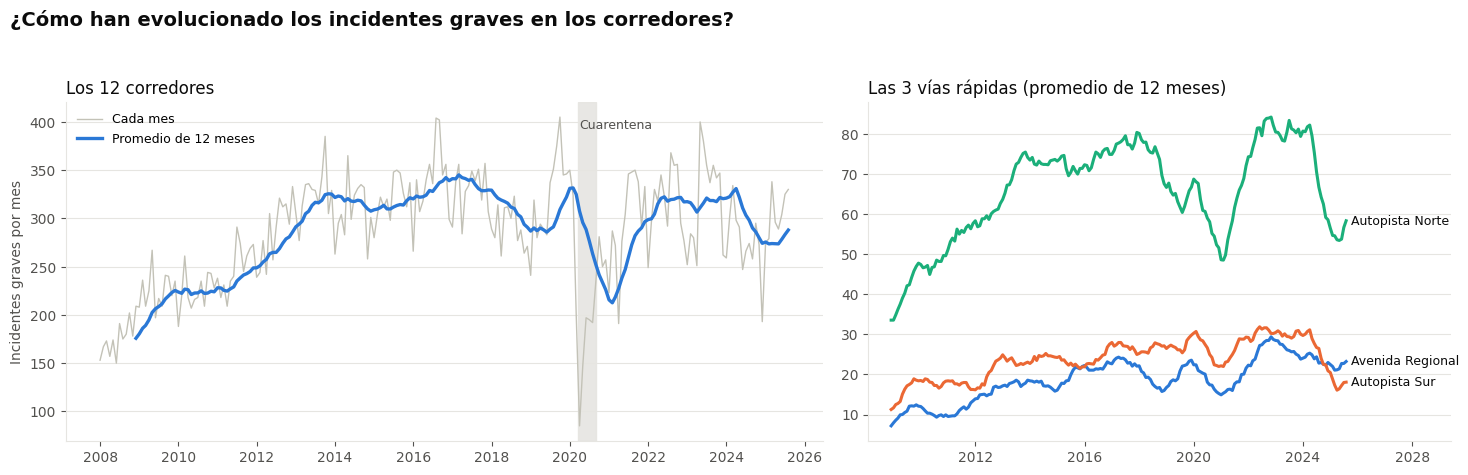

In [11]:
total = serie.groupby("periodo")["graves"].sum()
x = total.index.to_timestamp()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
ax1.plot(x, total.values, color="#c3c2b7", lw=1, label="Cada mes")
ax1.plot(x, total.rolling(12).mean().values, color=COLORES[0], lw=2.4, label="Promedio de 12 meses")
ax1.axvspan(pd.Timestamp("2020-03-20"), pd.Timestamp("2020-08-31"), color="#e6e5e1", alpha=0.9)
ax1.text(pd.Timestamp("2020-04-01"), total.max() * 0.97, "Cuarentena", fontsize=9, color=TINTA_2)
ax1.set_title("Los 12 corredores", loc="left", fontsize=12, color=TINTA)
ax1.set_ylabel("Incidentes graves por mes", color=TINTA_2); ax1.legend(frameon=False, fontsize=9)
for i, c in enumerate(RAPIDAS):
    s = serie[serie["corredor_id"] == c].set_index("periodo")["graves"].rolling(12).mean()
    ax2.plot(s.index.to_timestamp(), s.values, color=COLORES[i], lw=2.2)
    ax2.text(s.index[-1].to_timestamp() + pd.Timedelta(days=60), s.values[-1], NOMBRE[c], va="center", fontsize=9, color=TINTA)
ax2.set_xlim(right=pd.Timestamp("2029-06-01"))
ax2.set_title("Las 3 vías rápidas (promedio de 12 meses)", loc="left", fontsize=12, color=TINTA)
for ax in (ax1, ax2):
    estilo(ax)
fig.suptitle("¿Cómo han evolucionado los incidentes graves en los corredores?", x=0.01, ha="left",
             fontsize=14, weight="bold", color=TINTA)
plt.tight_layout(rect=(0, 0, 1, 0.94)); plt.show()

In [12]:
sin = d[d["lat"].isna()]
extra = pd.DataFrame({
    "sin_coordenadas": sin.groupby("ano").size(),
    "% que nombran un corredor": sin.groupby("ano")["nombra_corredor"].mean() * 100,
})
# ~40% de los que nombran un corredor quedan a ≤50 m cuando sí tienen coordenadas
extra["graves de corredor perdidos (aprox.)"] = (
    extra["sin_coordenadas"] * extra["% que nombran un corredor"] / 100 * 0.40
).round(0)
extra.round(1)

,sin_coordenadas,% que nombran un corredor,graves de corredor perdidos (aprox.)
ano,,,
2019,1252,13.7,69.0
2020,821,13.0,43.0
2021,926,16.1,60.0
2022,1128,17.2,78.0
2023,1358,16.9,92.0
2024,3109,0.0,0.0
2025,2478,24.9,246.0


### Conclusión de la parte 1

1. **El registro cambió en 2024 y eso se ve en los datos.** Los incidentes graves con coordenadas bajan de 94% a 86% de un año a otro. Los 3.109 que no tienen coordenadas tampoco tienen una dirección útil, así que no se pueden ubicar en ningún corredor. Sin corregir, los corredores parecen caer −22% (la ciudad cae −8%). Entre los que sí tienen coordenadas, la parte que cae en corredores se mantiene en 14,7%, dentro del rango 2019–2022 (14,2–15,4%).
2. **2025 tiene un problema distinto: menos precisión.** Solo el 34% de las direcciones que nombran un corredor quedan a ≤50 m, frente a ~40% en los años anteriores.
3. **Corregida la cobertura, la tendencia es creíble.** Los corredores suben hasta 2017, se estabilizan, caen en la cuarentena, se recuperan en 2022 y bajan en 2024 en línea con la ciudad. La excepción es la Autopista Norte, cuya baja (~−30%) es mayor que la del resto y no se explica solo por la cobertura.

**Decisión (D32).** Cada mes se divide por la cobertura de coordenadas de la ciudad en ese mes. Lo decidimos antes de evaluar los modelos. La prueba sigue en 2023–ago 2025 como se fijó, y 2023 se reporta aparte por ser el año limpio. La pérdida de precisión de 2025 y la baja de la Autopista Norte no se corrigen: quedan como límites de la proyección. El hallazgo pasa al cierre del notebook final como mejora concreta para MEData: un registro que pierde coordenadas sin aviso cambia lo que se concluye sobre las vías.

## 2 · Variables
- `mes`: estacionalidad (diciembre, vacaciones).
- `t`: meses desde enero de 2008 (tendencia).
- `pandemia`: marzo–agosto de 2020; `pandemia_hace_12`: el mismo periodo, un año después (para que el modelo no copie la caída en 2021).
- `post_pandemia`: desde septiembre de 2020 (posible cambio de nivel).
- `lag12`: el mismo mes del año anterior; `media_lag12`: el promedio de los 12 meses que terminan hace un año (meses t−23 a t−12).

In [13]:
s = serie.sort_values(["corredor_id", "periodo"]).copy()
s["mes"] = s["periodo"].dt.month
s["ano"] = s["periodo"].dt.year
s["t"] = (s["periodo"].dt.year - 2008) * 12 + s["periodo"].dt.month - 1
s["pandemia"] = s["periodo"].between(pd.Period("2020-03", "M"), pd.Period("2020-08", "M")).astype(int)
s["post_pandemia"] = (s["periodo"] >= pd.Period("2020-09", "M")).astype(int)
g = s.groupby("corredor_id")
s["pandemia_hace_12"] = g["pandemia"].shift(12)
s["lag12"] = g["graves"].shift(12)
s["media_lag12"] = g["graves"].transform(lambda v: v.shift(12).rolling(12).mean())
s = s.dropna(subset=["lag12", "media_lag12", "pandemia_hace_12"]).reset_index(drop=True)

entreno, prueba = s[s["ano"] <= 2022].copy(), s[s["ano"] >= 2023].copy()
print(f"Entrenamiento: {entreno['periodo'].min()} a {entreno['periodo'].max()} · {len(entreno):,} filas · {entreno['graves'].sum():,} incidentes")
print(f"Prueba:        {prueba['periodo'].min()} a {prueba['periodo'].max()} · {len(prueba):,} filas · {prueba['graves'].sum():,} incidentes")

Entrenamiento: 2009-12 a 2022-12 · 1,884 filas · 46,239 incidentes
Prueba:        2023-01 a 2025-08 · 384 filas · 9,571 incidentes


**Conclusión.** El entrenamiento empieza en diciembre de 2009 y no en enero de 2008, porque `media_lag12` necesita 23 meses de historia. Quedan 157 meses × 12 corredores = 1.884 filas y 46.239 incidentes graves (serie corregida por cobertura). La prueba cubre 32 meses (enero de 2023 a agosto de 2025): 384 filas y 9.571 incidentes. El promedio es casi el mismo en los dos periodos, unos 25 incidentes por corredor al mes, así que la prueba no es un periodo atípico por su tamaño. Ningún modelo ve datos posteriores a diciembre de 2022 cuando se ajusta.

**Decisión.** Se mantiene esta partición, fijada antes de ver los resultados. La cuarentena queda dentro del entrenamiento y se controla con `pandemia` y `pandemia_hace_12`, para que los modelos no aprendan la caída de 2020 ni la copien en 2021.

## 3 · Los modelos

#### 3.1 Dos referencias ingenuas
Un modelo solo sirve si le gana a lo obvio: **"igual que el mismo mes del año pasado"** y **"igual que el promedio del año pasado"**.

In [14]:
pred = {"Ingenuo · mismo mes del año pasado": prueba["lag12"].values,
        "Ingenuo · promedio del año pasado": prueba["media_lag12"].values}

#### 3.2 Binomial negativa
$\log E[\text{graves}] = \text{corredor} + \text{mes} + \beta_1 t + \beta_2\,\text{pandemia} + \beta_3\,\text{pandemia\_hace\_12} + \beta_4\,\text{post\_pandemia} + \beta_5 \log(1 + \text{media\_lag12})$

In [15]:
f_nb = ("graves ~ C(corredor_id) + C(mes) + t + pandemia + pandemia_hace_12 + post_pandemia"
        " + np.log1p(media_lag12)")
nb, alpha_nb = ajustar_nb(f_nb, entreno)
pred["Binomial negativa"] = nb.predict(prueba).values
claves = ["t", "pandemia", "pandemia_hace_12", "post_pandemia", "np.log1p(media_lag12)"]
coef = pd.DataFrame({"coef": nb.params[claves], "p": nb.pvalues[claves]})
coef["efecto"] = [f"{(np.exp(12 * coef.loc['t', 'coef']) - 1) * 100:+.1f}% por año",
                  *[f"×{np.exp(v):.2f}" for v in coef["coef"].iloc[1:]]]
print(f"alpha (sobredispersión): {alpha_nb:.3f}")
coef.round(4)

alpha (sobredispersión): 0.021


,coef,p,efecto
t,0.0017,0.0000,+2.0% por año
pandemia,-0.7001,0.0000,×0.50
pandemia_hace_12,-0.0710,0.0474,×0.93
post_pandemia,-0.1200,0.0000,×0.89
np.log1p(media_lag12),0.2664,0.0000,×1.31


#### 3.3 XGBoost
Árboles de decisión potenciados, con objetivo de Poisson (para conteos). Ventaja: capta relaciones no lineales e interacciones. Limitación: **no extrapola la tendencia** más allá de lo que vio.

In [16]:
VARS = ["mes", "t", "pandemia", "pandemia_hace_12", "post_pandemia", "lag12", "media_lag12"]

def matriz(d):
    X = pd.get_dummies(d[["corredor_id"]], dtype=int).join(d[VARS])
    return X.reindex(columns=columnas, fill_value=0)

columnas = pd.get_dummies(s[["corredor_id"]], dtype=int).columns.tolist() + VARS
xgb = XGBRegressor(objective="count:poisson", n_estimators=400, max_depth=4, learning_rate=0.05,
                   subsample=0.8, colsample_bytree=0.8, random_state=SEMILLA)
xgb.fit(matriz(entreno), entreno["graves"])
pred["XGBoost"] = xgb.predict(matriz(prueba))
importancia = pd.Series(xgb.feature_importances_, index=columnas).sort_values(ascending=False).head(8)
importancia.round(3).to_frame("importancia")

,importancia
corredor_id_AUT_NORTE,0.557
media_lag12,0.129
corredor_id_AV_PALMAS,0.110
corredor_id_CL_30,0.034
lag12,0.034
corredor_id_AV_ORIENTAL,0.024
corredor_id_AV_80,0.023
corredor_id_AV_FERROCARRIL,0.020


### Conclusión de la parte 3

Pusimos a competir tres formas de predecir los incidentes graves de cada corredor en cada mes:

1. **Modelos ingenuos (3.1).** Repiten el pasado: el mismo mes del año anterior, o el promedio del último año. No explican nada, pero cualquier modelo serio tiene que superarlos. Si no lo hace, no vale la pena usarlo.
2. **Binomial negativa (3.2).** Explica el número de incidentes con factores que se pueden leer:
   - El nivel propio de cada corredor.
   - La estacionalidad.
   - Una tendencia de +2% por año.
   - La cuarentena, que dejó los incidentes a la mitad.
   - Un nivel 11% más bajo después de la pandemia.
   - Una persistencia moderada de la historia reciente.

   Casi no le queda variación sin explicar (alpha = 0,021).
3. **XGBoost (3.3).** Aprende solo, sin una fórmula fija. Se apoya sobre todo en lo mismo que la binomial negativa: el nivel de cada corredor (encabezado por la Autopista Norte) y su historia reciente. Lo que no da es la medida de cuánto pesa cada cosa.

Los dos modelos de verdad llegan a lo mismo: **lo que más predice los incidentes de un corredor es el propio corredor y su pasado reciente**. El calendario y la tendencia solo ajustan alrededor de ese nivel. Esto tiene una consecuencia para el proyecto: los corredores peligrosos lo siguen siendo año tras año. Si no se actúa, el riesgo no baja solo.

**Decisión.** Los tres pasan a la evaluación (parte 4) con el mismo periodo de prueba y la misma métrica (desviación media de Poisson), fijados antes de ver los resultados. Si la binomial negativa queda a menos de 5% del mejor, se usa ella para la proyección, porque se puede explicar y simular. Si no, se usa el mejor y se declara.

## 4 · ¿Cuál predice mejor 2023–2025?

#### 4.1 Errores en la prueba
- **Desviación de Poisson:** el error adecuado para conteos (menor = mejor). Es el criterio de decisión.
- **MAE:** error promedio en incidentes por corredor y mes.
- **Total predicho contra observado:** si el modelo acierta el nivel general.
- Para que la comparación sea justa, ninguna predicción baja de 0,1 (un 0 exacto haría infinita la desviación).

In [18]:
y = prueba["graves"].values
filas = []
for nombre, p in pred.items():
    p = np.clip(p, 0.1, None)                    # un 0 exacto haría infinita la desviación
    filas.append({"modelo": nombre, "desviación Poisson": mean_poisson_deviance(y, p),
                  "MAE": mean_absolute_error(y, p), "RMSE": np.sqrt(mean_squared_error(y, p)),
                  "total predicho": p.sum(), "total observado": y.sum(),
                  "error del total %": (p.sum() / y.sum() - 1) * 100})
errores = pd.DataFrame(filas).set_index("modelo").sort_values("desviación Poisson")
mejor = errores.index[0]
dif_nb = (errores.loc["Binomial negativa", "desviación Poisson"] / errores.loc[mejor, "desviación Poisson"] - 1) * 100
elegido = "Binomial negativa" if dif_nb < 5 else mejor
print(f"Menor desviación: {mejor} · la binomial negativa está {dif_nb:.1f}% por encima → se usa: {elegido}")
errores.round(2)

Menor desviación: Binomial negativa · la binomial negativa está 0.0% por encima → se usa: Binomial negativa


,desviación Poisson,MAE,RMSE,total predicho,total observado,error del total %
modelo,,,,,,
Binomial negativa,2.36,6.22,8.79,10515.06,9571,9.86
Ingenuo · promedio del año pasado,2.48,6.20,9.02,10110.33,9571,5.64
Ingenuo · mismo mes del año pasado,3.74,7.59,10.70,9921.20,9571,3.66
XGBoost,4.33,9.03,11.29,12398.97,9571,29.55


In [21]:
filas = []
for etiqueta, m in [("2023", prueba["periodo"].dt.year == 2023),
                    ("2024 – ago 2025", prueba["periodo"].dt.year >= 2024)]:
    yy = prueba.loc[m, "graves"].values
    for nombre, p in pred.items():
        pp = np.clip(np.asarray(p)[m.values], 0.1, None)
        filas.append({"periodo": etiqueta, "modelo": nombre,
                      "desviación Poisson": mean_poisson_deviance(yy, pp),
                      "error del total %": (pp.sum() / yy.sum() - 1) * 100})
pd.DataFrame(filas).pivot(index="modelo", columns="periodo").round(2)

desviación Poisson                  \
periodo                                          2023 2024 – ago 2025   
modelo                                                                  
Binomial negativa                                1.73            2.73   
Ingenuo · mismo mes del año pasado               2.57            4.45   
Ingenuo · promedio del año pasado                2.01            2.76   
XGBoost                                          3.59            4.78   

                                   error del total %                  
periodo                                         2023 2024 – ago 2025  
modelo                                                                
Binomial negativa                               0.98           15.83  
Ingenuo · mismo mes del año pasado             -1.04            6.81  
Ingenuo · promedio del año pasado              -1.73           10.58  
XGBoost                                        20.80           35.42

#### 4.2 Por corredor: total de la prueba

In [22]:
por_corr = prueba.assign(**{k: v for k, v in pred.items()}).groupby("corredor_id")[["graves", *pred]].sum()
por_corr.index = por_corr.index.map(NOMBRE)
por_corr.round(0).astype(int)

,graves,Ingenuo · mismo mes del año pasado,Ingenuo · promedio del año pasado,Binomial negativa,XGBoost
corredor_id,,,,,
Autopista Norte,2161,2447,2549,2506,2670
Autopista Sur,766,912,959,909,1042
Avenida 33,635,709,733,791,955
Avenida 80,938,826,815,877,991
Avenida Ferrocarril,430,404,408,495,676
Avenida Guayabal,778,743,745,898,957
Avenida Oriental,881,891,904,987,1043
Avenida Las Palmas,118,126,133,124,327
Avenida El Poblado,614,634,643,726,926


#### 4.3 Las 3 vías rápidas: observado contra predicho

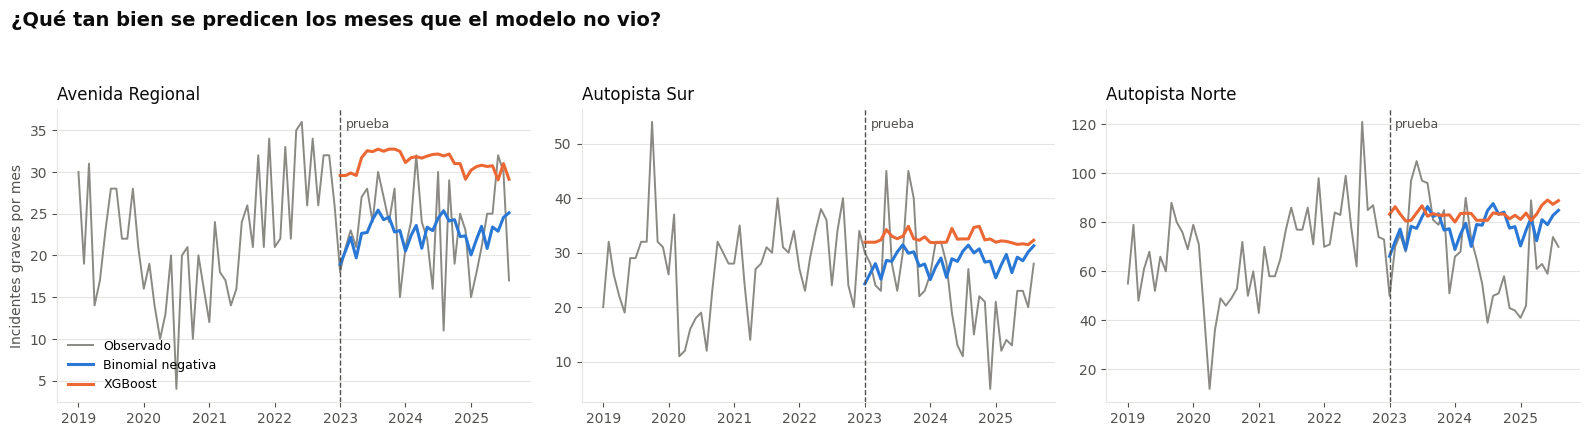

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), sharey=False)
for ax, c in zip(axes, RAPIDAS):
    hist = s[(s["corredor_id"] == c) & (s["ano"] >= 2019)].set_index("periodo")["graves"]
    m = prueba["corredor_id"].values == c
    xp = prueba.loc[m, "periodo"].dt.to_timestamp()
    ax.plot(hist.index.to_timestamp(), hist.values, color="#8a8984", lw=1.4, label="Observado")
    ax.plot(xp, pred["Binomial negativa"][m], color=COLORES[0], lw=2.2, label="Binomial negativa")
    ax.plot(xp, pred["XGBoost"][m], color=COLORES[1], lw=2.2, label="XGBoost")
    ax.axvline(pd.Timestamp("2023-01-01"), color=TINTA_2, lw=1, ls="--")
    ax.text(pd.Timestamp("2023-02-01"), ax.get_ylim()[1] * 0.97, "prueba", fontsize=9, color=TINTA_2, va="top")
    ax.set_title(NOMBRE[c], loc="left", fontsize=12, color=TINTA)
    estilo(ax)
axes[0].set_ylabel("Incidentes graves por mes", color=TINTA_2)
axes[0].legend(frameon=False, fontsize=9, loc="lower left")
fig.suptitle("¿Qué tan bien se predicen los meses que el modelo no vio?", x=0.01, ha="left",
             fontsize=14, weight="bold", color=TINTA)
plt.tight_layout(rect=(0, 0, 1, 0.92)); plt.show()

### Conclusión de la parte 4

1. **La binomial negativa es el mejor modelo**, aunque por poco: es 5% mejor que repetir el promedio del año pasado y bastante mejor que XGBoost, que ni siquiera supera a los modelos ingenuos.
2. **El modelo más complejo no fue el mejor.** Con 12 corredores y conteos mensuales, un modelo que se puede explicar le gana a uno de caja negra.
3. **Todos sobrestiman 2023–2025**, porque la Autopista Norte y la Autopista Sur bajaron en 2024 más de lo esperado. Puede ser un cambio real o un problema del registro en esas vías (parte 1); con estos datos no se puede separar.
4. **Para el proyecto, la conclusión no cambia:** el ranking de corredores se mantiene. Las vías con más incidentes antes de la prueba siguen siendo las que tienen más durante la prueba.

**Decisión.** La proyección de la parte 5 se hace con la binomial negativa y un intervalo de 90%. Las cifras de la Autopista Norte y la Autopista Sur llevan la advertencia de posible sobrestimación.

## 5 · Si no hacemos nada: los próximos 12 meses
Proyección de septiembre de 2025 a agosto de 2026 con el modelo elegido, reentrenado con todos los meses hasta agosto de 2025. Los valores de "hace 12 meses" ya son conocidos (septiembre de 2024 a agosto de 2025).
El intervalo de la binomial negativa se obtiene simulando 5.000 años posibles con su sobredispersión.

In [24]:
todo = s.copy()
futuro_p = pd.period_range("2025-09", "2026-08", freq="M")
hist = serie.set_index(["corredor_id", "periodo"])["graves"].sort_index()
filas = []
for c in CORREDORES:
    h = hist.loc[c]
    for p in futuro_p:
        filas.append({"corredor_id": c, "periodo": p, "mes": p.month, "ano": p.year,
                      "t": (p.year - 2008) * 12 + p.month - 1, "pandemia": 0, "pandemia_hace_12": 0, "post_pandemia": 1,
                      "lag12": h.loc[p - 12], "media_lag12": h.loc[p - 23: p - 12].mean()})
futuro = pd.DataFrame(filas)

if elegido == "XGBoost":
    modelo_final = XGBRegressor(**xgb.get_params()).fit(matriz(todo), todo["graves"])
    futuro["prediccion"] = modelo_final.predict(matriz(futuro))
    intervalos = None
else:
    modelo_final, _ = ajustar_nb(f_nb, todo)
    futuro["prediccion"] = modelo_final.predict(futuro)

_, alpha = ajustar_nb(f_nb, todo)                                             # sobredispersión para el intervalo
rng = np.random.default_rng(SEMILLA)
mu = futuro["prediccion"].values
if alpha > 1e-6:
    n = 1 / alpha
    sims = rng.negative_binomial(n, n / (n + mu), size=(5000, len(mu)))        # 5.000 años posibles
else:
    sims = rng.poisson(mu, size=(5000, len(mu)))
futuro_sims = pd.DataFrame(sims.T, index=futuro["corredor_id"]).groupby(level=0).sum()

ultimo = hist.loc[(slice(None), slice(pd.Period("2024-09", "M"), pd.Period("2025-08", "M")))].groupby(level=0).sum()
proy = pd.DataFrame({"últimos 12 meses (sep 2024 – ago 2025)": ultimo,
                     "proyección (sep 2025 – ago 2026)": futuro.groupby("corredor_id")["prediccion"].sum(),
                     "IC 90% inferior": futuro_sims.quantile(0.05, axis=1),
                     "IC 90% superior": futuro_sims.quantile(0.95, axis=1)})
proy["cambio %"] = (proy["proyección (sep 2025 – ago 2026)"] / proy["últimos 12 meses (sep 2024 – ago 2025)"] - 1) * 100
proy = proy.sort_values("proyección (sep 2025 – ago 2026)", ascending=False)
proy.to_csv("data/processed/proyeccion_12_meses.csv")
proy.index = proy.index.map(NOMBRE)
print(f"Modelo usado: {elegido}")
proy.round(1)

Modelo usado: Binomial negativa


,últimos 12 meses (sep 2024 – ago 2025),proyección (sep 2025 – ago 2026),IC 90% inferior,IC 90% superior,cambio %
corredor_id,,,,,
Autopista Norte,701,834.8,756.0,914.1,19.1
Avenida Oriental,332,352.7,312.0,395.0,6.2
Avenida San Juan,358,341.7,302.0,382.0,-4.5
Avenida 80,375,337.2,299.0,376.0,-10.1
Avenida Guayabal,316,330.7,292.0,371.0,4.6
Autopista Sur,217,294.0,259.0,330.0,35.5
Avenida 33,195,271.0,238.0,306.0,39.0
Avenida Regional,279,263.4,231.0,298.0,-5.6
Avenida El Poblado,236,256.7,225.0,290.0,8.8


**Conclusión.** Si nada cambia, la binomial negativa proyecta 3.732 incidentes graves en los 12 corredores entre septiembre de 2025 y agosto de 2026. En los últimos 12 meses hubo 3.455 (+8%). Pero el aumento se concentra en las mismas vías que el modelo sobrestimó en la prueba: la Autopista Norte (+19% proyectado; +16% de exceso en la prueba), la Autopista Sur (+36%; +19%) y la Avenida 33 (+39%; +25%). Esas cifras no anuncian un empeoramiento. Muestran que el modelo espera que esas vías vuelvan a su nivel de antes de 2024. En el resto de corredores la proyección cambia poco (entre −14% y +9%).

El intervalo de 90% solo recoge el azar del conteo mes a mes, no el error del modelo. Por eso es estrecho: en la Autopista Norte va de 756 a 914 y deja por fuera los 701 del último año.

Lo que sí es firme es el orden. La Autopista Norte, con 700 a 835 incidentes graves al año, tiene más del doble que cualquier otro corredor. Le siguen la Oriental, San Juan, la 80 y Guayabal, con 330 a 375 cada uno.

**Decisión (D33).** "No actuar" se reporta como un rango, no como una cifra: entre 3.455 (si se repite el último año) y 3.732 (si se cumple el modelo) incidentes graves al año en los 12 corredores. Son **unos 10 incidentes graves al día en solo 12 vías**. Las vidas salvadas del Monte Carlo no salen de esta proyección, sino de los muertos del Distrito por corredor (D17).

## 6 · Resumen

**Pregunta.** Si Medellín no hace nada, ¿cuántos incidentes graves habrá en los 12 corredores el próximo año, y en cuáles?

**Datos.** 55.903 incidentes graves (heridos y muertos) del ITM asignados a los 12 corredores entre 2008 y agosto de 2025, contados por corredor y mes. Entrenamiento hasta diciembre de 2022; prueba de enero de 2023 a agosto de 2025.

**Resultados**

1. **El registro cambió en 2024.** Los incidentes con coordenadas bajan de 94% a 86% y los que faltan no tienen una dirección útil. Sin corregir, los corredores parecen caer −22% (la ciudad cae −8%). Entre los que sí tienen coordenadas, la parte que cae en corredores no cambia (14,7%). La serie se corrige por la cobertura de cada mes (D32).
2. **Los corredores peligrosos lo siguen siendo.** En los dos modelos, lo que más predice los incidentes de un corredor es el propio corredor y su historia. El calendario y la tendencia (+2% por año) solo ajustan alrededor de ese nivel. La cuarentena los dejó a la mitad, y después de la pandemia el nivel quedó 11% más bajo.
3. **El modelo que se puede explicar ganó.** La binomial negativa tuvo el menor error (desviación 2,36), un poco mejor que repetir el promedio del año pasado (2,48). XGBoost fue el peor (4,33): no superó a los modelos ingenuos y se pasó en todos los corredores.
4. **Todos sobrestimaron 2023–2025.** La binomial negativa se pasó en +9,9%, sobre todo en la Autopista Norte (+16%), la Autopista Sur (+19%) y la Avenida 33 (+25%). Esas vías bajaron en 2024 más de lo que explica la cobertura, y no se puede saber si fue un cambio real o un problema del registro en esas zonas.
5. **"No actuar" son entre 3.455 y 3.732 incidentes graves al año en los 12 corredores, unos 10 al día.** El aumento proyectado en la Autopista Norte, la Autopista Sur y la Avenida 33 repite el sesgo de la prueba, así que no se presenta como un empeoramiento esperado (D33).
6. **La Autopista Norte es otro nivel:** entre 700 y 835 incidentes graves al año, más del doble que cualquier otro corredor.

**Límites**
- El intervalo de 90% solo recoge el azar del conteo, no el error del modelo. Es más estrecho de lo que debería.
- Desde 2025 la ubicación es menos precisa (34% a ≤50 m, frente a ~40%), y eso no se corrigió.
- La corrección por cobertura supone que los incidentes sin coordenadas se reparten como los demás. En 2024 no se puede comprobar, porque esos registros no tienen dirección.
- XGBoost no se ajustó con un periodo de validación. Un XGBoost mejor ajustado podría quedar más cerca, pero no se ajusta con la prueba.

**Qué pasa al proyecto**
- **Al notebook final (punto 10, "no actuar"):** "unos 10 incidentes graves al día en solo 12 vías", y la Autopista Norte como el corredor que más pesa.
- **Al punto 13 (mejoras a MEData):** en 2024 el registro perdió coordenadas y direcciones sin aviso, y eso basta para cambiar lo que se concluye sobre las vías.
- **Al Monte Carlo:** el orden de los corredores y la persistencia del riesgo. Las vidas salvadas se calculan con los muertos del Distrito (D17), no con esta proyección.